In [1]:
import xspec
import numpy as np
import os
import subprocess
import matplotlib.pyplot as plt
import re
import pandas as pd
from astropy.io import fits
import csv
import time
from astropy.time import Time

In [2]:
start_time = time.time()

In [192]:
os.chdir('/work2/sruedavargas/SAS-software/products/spectra_files')

# Path where .csv file with energy ranges is located 
file_path = "/work2/sruedavargas/energies_epatplot.csv"
source = 'NGC5506'

In [4]:
# Reading file with energy ranges 

df = pd.read_csv(file_path, header=[1], index_col=[0,1])

In [5]:

# Taking into account all observations

mos1_av_spec=[]
mos2_av_spec=[]
pn0_av_spec=[]
pn14_av_spec=[]


for file in os.listdir():
    if file.startswith('av_spec') and file.endswith('_grp20.ds'):
        if 'MOS1' in file:
            mos1_av_spec.append(file)
        elif 'MOS2' in file:
            mos2_av_spec.append(file)
        elif 'PN' and 'pat0' in file:
            pn0_av_spec.append(file)
        elif 'PN' and 'pat14' in file:
            pn14_av_spec.append(file)


                  
mat_av_spec=[]

for file1 in mos1_av_spec:
    obs_id_1 = f"{file1.split('_')[2]}"
    camera_1 = f"{file1.split('_')[3]}"
    en_1 = f"{file1.split('_')[4]}"
    row=[file1]
    
    for file2 in mos2_av_spec:
        obs_id_2 = f"{file2.split('_')[2]}"
        camera_2 = f"{file2.split('_')[3]}"
        en_2 = f"{file2.split('_')[4]}"
      
        if obs_id_1==obs_id_2 and en_1==en_2:
            row.append(file2)
            
            for file3 in pn0_av_spec:
                obs_id_3 = f"{file3.split('_')[2]}"
                camera_3 = f"{file3.split('_')[3]}"
                en_3 = f"{file3.split('_')[4]}"

                if obs_id_1==obs_id_3 and en_1==en_3:
                    row.append(file3)
                    
                    for file4 in pn14_av_spec:
                        obs_id_4 = f"{file4.split('_')[2]}"
                        camera_4 = f"{file4.split('_')[3]}"
                        en_4 = f"{file4.split('_')[4]}"

                        if obs_id_1==obs_id_4 and en_1==en_4:
                            row.append(file4)
                    
                          
    if len(row) >= 4:
        mat_av_spec.append(row)   

In [6]:
xchat = xspec.Xset.chatter, xspec.Xset.logChatter
xspec.Xset.chatter    = 0
xspec.Xset.logChatter = 0

In [7]:
# Defining data frame that will contain all the results from all observations

column_names = ["av_nh_val", "av_gamma_val", "points_plot", 
             "nh_values_nh_free", "error_plot_nh_nh_free", 
            "nh_values_nhgamma_free", "error_plot_nh_nhgamma_free",
            "gamma_values_nhgamma_free", "error_plot_gamma_nhgamma_free","time_values", 
            "chi2_dof_nh_free", "chi2_dof_nhgamma_free",
            "plot_flux_02_10", "plot_flux_02_2", "HR", "hr_uncertainities"]

results_object = pd.DataFrame(columns=column_names)

In [8]:
for spectral_set in mat_av_spec:
    
    xspec.AllData.clear()
    
    # Defining spectral set with averga espectra
    
    mos1_12_data = spectral_set[0]
    mos2_12_data = spectral_set[1]
    pn_0_data = spectral_set[2]
    pn_14_data = spectral_set[3]
    
    obs_id=f"{mos1_12_data.split('_')[2]}"
    energy = f"{mos1_12_data.split('_')[4]}"
    
    # Loading average spectra data into xspec


    xspec.AllData(f"1:1 {mos1_12_data} 2:2 {mos2_12_data} 3:3 {pn_0_data} 4:4 {pn_14_data} ")

    xspec.AllData.notice('all')
    xspec.AllData.ignore('bad')

    in_exp_id=f"id{obs_id}"
    in_exp_en=f"{energy}"

    # Defining energies by reading the .csv loaded initially

    mos1_en=df.loc[in_exp_id,in_exp_en]['MOS1 pat. 1-12']
    mos2_en=df.loc[in_exp_id,in_exp_en]['MOS2 pat. 1-12']
    pn0_en=df.loc[in_exp_id,in_exp_en]['PN pat. 0']
    pn14_en=df.loc[in_exp_id,in_exp_en]['PN pat. 1-4']


    low_mos1=f"{mos1_en.split('-')[0]}"
    up_mos1=f"{mos1_en.split('-')[1]}"
    low_mos2=f"{mos2_en.split('-')[0]}"
    up_mos2=f"{mos2_en.split('-')[1]}"
    low_pn_0=f"{pn0_en.split('-')[0]}"
    up_pn_0=f"{pn0_en.split('-')[1]}"
    low_pn_14=f"{pn14_en.split('-')[0]}"
    up_pn_14=f"{pn14_en.split('-')[1]}"


    xspec.AllData(1).ignore(f"**-{low_mos1} {up_mos1}-**")
    xspec.AllData(2).ignore(f"**-{low_mos2} {up_mos2}-**")
    xspec.AllData(3).ignore(f"**-{low_pn_0} {up_pn_0}-**")
    xspec.AllData(4).ignore(f"**-{low_pn_14} {up_pn_14}-**")

    # Setting constants

    xspec.Xset.abund = 'wilm' 
    xspec.Xset.xsect = 'vern' 
    xspec.Xset.cosmo = '70 0 0.73'

    z_opt = 0.0061 # from Laha
    nH    = 4.08e-2

    # Defining model for NGC 5506

    xspec.AllModels += ("constant(TBabs*(zTBabs*(apec+powerlaw)+zgauss+zTBabs*(pexrav+zgauss+zgauss)))")
    mod1 = xspec.AllModels(1)

    # Defining model parameters for this object NGC 5506

    mod1.constant.factor.values=(1,-1)

    mod1.TBabs.nH.values = (nH, -1)

    mod1.zTBabs.nH.values = (0.0846928, 0.01, 0, 0, 1e+5, 1e+5) 
    mod1.zTBabs.Redshift.values = (z_opt, -1)

    mod1.apec.kT.values = (0.8861671, -1) #f
    mod1.apec.Abundanc. values = (1, -1)
    mod1.apec.Redshift.values = (z_opt, -1)
    mod1.apec.norm.values = (3.14725e-05, 0.01, 0, 0, 1e+10, 1e+10) 

    mod1.powerlaw.PhoIndex.values = (1.764608, 0.1, 1.6, 1.6, 1.99, 1.99)
    mod1.powerlaw.PhoIndex.link = mod1.pexrav.PhoIndex
    mod1.powerlaw.norm.values = (0.0003498589, 0.01, 0, 0, 1e+10, 1e+10)

    mod1.zgauss.LineE.values = (0.5657432, -1) #f
    mod1.zgauss.Sigma.values = (0, -1) #f 
    mod1.zgauss.Redshift.values = (0, -1)
    mod1.zgauss.norm.values = (1.627922e-05, 0.01, 0, 0, 1e+10, 1e+10)

    mod1.zTBabs_7.nH.values = (2.761, 0.1, 0, 0, 100000, 100000)
    mod1.zTBabs_7.Redshift.values = (z_opt, -1)

    mod1.pexrav.PhoIndex.values = (1.764608, 0.1, 1.6, 1.6, 1.99, 5)
    mod1.pexrav.foldE.values = (100., -1)
    mod1.pexrav.rel_refl.values = (2, -1)
    mod1.pexrav.Redshift.values = (nH, -1)
    mod1.pexrav.abund.values = (1,-1)
    mod1.pexrav.Fe_abund.values = (1, -1)
    mod1.pexrav.cosIncl.values = (0.45, -1)
    mod1.pexrav.norm.values = (0.01804564, 0.01, 0, 0, 1e+10, 1e+10)

    mod1.zgauss_9.LineE.values = (6.363523, -1) #f
    mod1.zgauss_9.Sigma.values = (0, -1) #f
    mod1.zgauss_9.Redshift.values = (nH, -1)
    mod1.zgauss_9.norm.values = (4.28059e-05, 0.01, 0, 0, 1e+10, 1e+10)

    mod1.zgauss_10.LineE.values = (6.64431, -1) #f
    mod1.zgauss_10.Sigma.values = (0.2, -1) #f
    mod1.zgauss_10.Redshift.values = (nH, -1)
    mod1.zgauss_10.norm.values = (6.47984e-05, 0.01, 0, 0, 1e+10, 1e+10) 

    xspec.AllModels(2).constant.factor.untie()
    xspec.AllModels(2).constant.factor.values = (1, 0.01, 0.5, 0.5, 1.5, 1.5)
    xspec.AllModels(3).constant.factor.untie()
    xspec.AllModels(3).constant.factor.values = (1, 0.01, 0.5, 0.5, 1.5, 1.5)
    xspec.AllModels(4).constant.factor.untie()
    xspec.AllModels(4).constant.factor.values = (1, 0.01, 0.5, 0.5, 1.5, 1.5)

    #Defining statistics

    xspec.Fit.statMethod = "chi"


    #Running fit multiple times to get decrease the chi2

    xspec.Fit.perform()
    xspec.Fit.perform()
    xspec.Fit.perform()

    av_nh_val=mod1.zTBabs_7.nH.values[0]
    av_gamma_val=mod1.pexrav.PhoIndex.values[0]

    model_values=[]

    for ie in range(1,33):

        value=mod1(ie).values[0]   
        model_values.append(value)



    constant_values=[]

    for io in range(2,5):
        value=xspec.AllModels(io).constant.factor.values[0]
        constant_values.append(value)
    
    # Selecting single spectra corresponding to the observation and threshold

    mos1_sing_spec=[]
    mos2_sing_spec=[]
    pn0_sing_spec=[]
    pn14_sing_spec=[]

    for file in os.listdir():

        if file.startswith(f'sing_spec_{obs_id}') and file.endswith('_grp20.ds') and f"{energy}" in file:

            if 'MOS1' in file:
                mos1_sing_spec.append(file)
            elif 'MOS2' in file:
                mos2_sing_spec.append(file)
            elif 'PN' and 'pat0' in file:
                pn0_sing_spec.append(file)
            elif 'PN' and 'pat14' in file:
                pn14_sing_spec.append(file)
                


    # Sorting single spectra in order of bins

    def sort_key(item):

        match = re.search(r'(\d+)_src', item)
        if match:
            return int(match.group(1))
        return 0


    mos1_sing_spec_sorted = sorted(mos1_sing_spec, key=sort_key)
    mos2_sing_spec_sorted = sorted(mos2_sing_spec, key=sort_key)
    pn0_sing_spec_sorted = sorted(pn0_sing_spec, key=sort_key)
    pn14_sing_spec_sorted = sorted(pn14_sing_spec, key=sort_key)


    # Recovering averge spectra model values

    def ret_model_values():

        for ele in zip(range(1,33), model_values):
            mod1(ele[0]).values=(ele[1],-1.)


        mod1.powerlaw.PhoIndex.frozen = False    
        mod1.powerlaw.PhoIndex.link = mod1.pexrav.PhoIndex


        for io in zip(range(2,5), constant_values):
            xspec.AllModels(io[0]).constant.factor.values=(io[1],-1)


    #Getting spectra that do not contain data

    def empty(spec_set):

        data_spec_files=[]

        for file in spec_set:

            with fits.open(file) as f:
                header_spec = f[1].header
                try:
                    a = header_spec['EXPOSURE']
                except:
                    print(f"No data in spectrum {file}")
                else:
                    data_spec_files.append(file)

        return(data_spec_files)


    # Writing expression for data based on spectral set 


    def data_expression(n_set, spectral_set):

        data_spec_expression=""
        n_list=[]
        exp_n_ar=[]

        for file in spectral_set:

            data_spec_expression+=f"{n_set}:{n_set} {file} "
            exp_n_ar.append((n_set, file))

            n_set+=1

        return(data_spec_expression, exp_n_ar)


    #Defining the energy range for each spectrum in the spectral set

    def energies_spec(array_spec_set):

        for element in array_spec_set:

            data_group=element[0]
            spectrum_file=element[1]

            if 'MOS1' in spectrum_file:

                xspec.AllData(data_group).ignore(f"**-{low_mos1} {up_mos1}-**")

            elif 'MOS2' in spectrum_file:

                xspec.AllData(data_group).ignore(f"**-{low_mos2} {up_mos2}-**")

            elif 'PN' and 'pat0' in spectrum_file:

                xspec.AllData(data_group).ignore(f"**-{low_pn_0} {up_pn_0}-**")

            elif 'PN' and 'pat14' in spectrum_file:

                xspec.AllData(data_group).ignore(f"**-{low_pn_14} {up_pn_14}-**")


    # Fitting single spectra


    n_expression=1

    nh_values_nh_free=[]
    nh_error_nh_free=[]


    chi2_nh_free=[]
    dof_nh_free=[]

    flux_02_10=[]
    flux_02_2=[]
    flux_2_10=[]


    nh_values_nhgamma_free=[]
    nh_error_nhgamma_free=[]

    gamma_values_nhgamma_free=[]
    gamma_error_nhgamma_free=[]


    chi2_nhgamma_free=[]
    dof_nhgamma_free=[]



    for spset in zip(mos1_sing_spec_sorted,mos2_sing_spec_sorted,pn0_sing_spec_sorted,pn14_sing_spec_sorted):

        xspec.AllData.clear()

        use_files=empty(spset)
        expression_funct=data_expression(n_expression, use_files)

        data_exp_xspec=expression_funct[0]
        arr_set_en=expression_funct[1]

        xspec.AllData(f"{data_exp_xspec}")

        xspec.AllData.notice('all')
        xspec.AllData.ignore('bad')

        energies_spec(arr_set_en)

        ret_model_values()


        nh_par = mod1.zTBabs_7.nH
        phoindex_par = mod1.pexrav.PhoIndex

     #N_H and norm powerlaw free

        mod1(15).frozen = False
        mod1(24).frozen = False
        xspec.Fit.perform()
        nh_values_nh_free.append(nh_par.values[0])

        xspec.Fit.error('2.706 15')
        nh_error_nh_free.append(nh_par.error)

        chi2_nh_free_val=xspec.Fit.statistic
        chi2_nh_free.append(chi2_nh_free_val)

        dof_nh_free_val=xspec.Fit.dof
        dof_nh_free.append(dof_nh_free_val)

        xspec.AllModels.calcFlux('0.2 10.0 err 20 90')
        flux_02_10_val=xspec.AllData(3).flux
        flux_02_10.append(flux_02_10_val)

        xspec.AllModels.calcFlux('0.2 2.0 err 20 90')
        flux_02_2_val=xspec.AllData(3).flux
        flux_02_2.append(flux_02_2_val)
        
        xspec.AllModels.calcFlux('2.0 10.0 err 20 90')
        flux_2_10_val=xspec.AllData(3).flux
        flux_2_10.append(flux_2_10_val) 



    # N_H, gamma, and norm powerlaw free


        mod1(17).frozen = False
        xspec.Fit.perform()
        nh_values_nhgamma_free.append(nh_par.values[0])
        gamma_values_nhgamma_free.append(phoindex_par.values[0])

        chi2_nhgamma_free_val=xspec.Fit.statistic
        chi2_nhgamma_free.append(chi2_nhgamma_free_val)

        dof_nhgamma_free_val=xspec.Fit.dof
        dof_nhgamma_free.append(dof_nhgamma_free_val)

        xspec.Fit.error('2.706 15')
        nh_error_nhgamma_free.append(nh_par.error)

        xspec.Fit.error('2.706 17')
        gamma_error_nhgamma_free.append(phoindex_par.error)


    chi2_dof_nh_free=np.divide(chi2_nh_free, dof_nh_free)
    chi2_dof_nhgamma_free=np.divide(chi2_nhgamma_free, dof_nhgamma_free) 


    bin_gti=f"bin_gti_{obs_id}_PN_{energy}.fits"
    time_values=[]


    with fits.open(bin_gti) as f:
        data = f[1].data
        start=data.field(0)
        stop=data.field(1)

        for i in range(len(data)):
            start = data[i][0]
            stop = data[i][1]
            time_val = (stop + start)/2
            time_values.append(time_val)


    points_plot=np.arange(1,len(nh_values_nh_free)+1,1)   

    # Calculating errors for plot

    def low_upper_error(values, errors):

        lower_errors = [values[i]-point[0]  for i, point in enumerate(errors)]
        upper_errors = [point[1] - values[i] for i, point in enumerate(errors)]

        return(lower_errors, upper_errors)


    error_plot_nh_nh_free=low_upper_error(nh_values_nh_free, nh_error_nh_free)
    error_plot_nh_nhgamma_free=low_upper_error(nh_values_nhgamma_free, nh_error_nhgamma_free)
    error_plot_gamma_nhgamma_free=low_upper_error(gamma_values_nhgamma_free, gamma_error_nhgamma_free)

    def flux(result_flux):

        value=[]
        lower=[]
        upper=[]

        for element in result_flux:


            lower_errors = element[0]-element[1]
            upper_errors = element[2] - element[0]

            lower.append(lower_errors)
            upper.append(upper_errors)
            value.append(element[0])


        return(value, lower, upper)

    plot_flux_02_10=flux(flux_02_10)
    plot_flux_02_2=flux(flux_02_2)
    plot_flux_2_10=flux(flux_2_10)

    # Calculating Hardness ratio

    hr1 = np.subtract(plot_flux_02_10[0],plot_flux_02_2[0])
    hr2 = np.add(plot_flux_02_10[0],plot_flux_02_2[0])
    HR = np.divide(hr1,hr2)
    
    # Calculating uncertainity in hardness ratio
    
    def hr_unc(hard,soft,n_lim):
        exp1=np.square(hard[n_lim])*np.square(soft[0])
        exp2=np.square(soft[n_lim])*np.square(hard[0])
        exp3=np.divide(4,np.power(np.add(hard[0],soft[0]),4))
        exp4=np.multiply(exp3,np.add(exp1,exp2))
        exp5=np.sqrt(exp4)
        return(exp5)


    low_hr_unc=hr_unc(plot_flux_2_10,plot_flux_02_2,1)
    up_hr_unc=hr_unc(plot_flux_2_10,plot_flux_02_2,2)

    hr_uncertainities=[low_hr_unc,up_hr_unc]
    
    
    
    results={"av_nh_val": av_nh_val, "av_gamma_val": av_gamma_val, "points_plot": points_plot, 
             "nh_values_nh_free":nh_values_nh_free, "error_plot_nh_nh_free":error_plot_nh_nh_free, 
            "nh_values_nhgamma_free":nh_values_nhgamma_free, "error_plot_nh_nhgamma_free": error_plot_nh_nhgamma_free,
            "gamma_values_nhgamma_free":gamma_values_nhgamma_free, 'error_plot_gamma_nhgamma_free':error_plot_gamma_nhgamma_free, "time_values":time_values, 
            "chi2_dof_nh_free":chi2_dof_nh_free, "chi2_dof_nhgamma_free":chi2_dof_nhgamma_free,
            "plot_flux_02_10":plot_flux_02_10, "plot_flux_02_2":plot_flux_02_2, "plot_flux_2_10":plot_flux_2_10,
             "HR":HR, "hr_uncertainities":hr_uncertainities}
    
    results_df = pd.DataFrame([results], index=[f"{obs_id}_{energy}"])
    
    results_object = pd.concat([results_object, results_df])
    
    
    
    
    


    

tbvabs Version 2.3
Cosmic absorption with grains and H2, modified from
Wilms, Allen, & McCray, 2000, ApJ 542, 914-924
Questions: Joern Wilms
joern.wilms@sternwarte.uni-erlangen.de
joern.wilms@fau.de

http://pulsar.sternwarte.uni-erlangen.de/wilms/research/tbabs/

PLEASE NOTICE:
To get the model described by the above paper
you will also have to set the abundances:
   abund wilm

Note that this routine ignores the current cross section setting
as it always HAS to use the Verner cross sections as a baseline.


Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? Number of 

In [9]:
end_time = time.time()
elapsed_time = end_time - start_time
print(elapsed_time)

5921.376564502716


In [10]:
results_object.to_csv('results_object.csv', sep=',', index=True, encoding='utf-8')

In [11]:
time_sorted_results_object=results_object.sort_values('time_values')

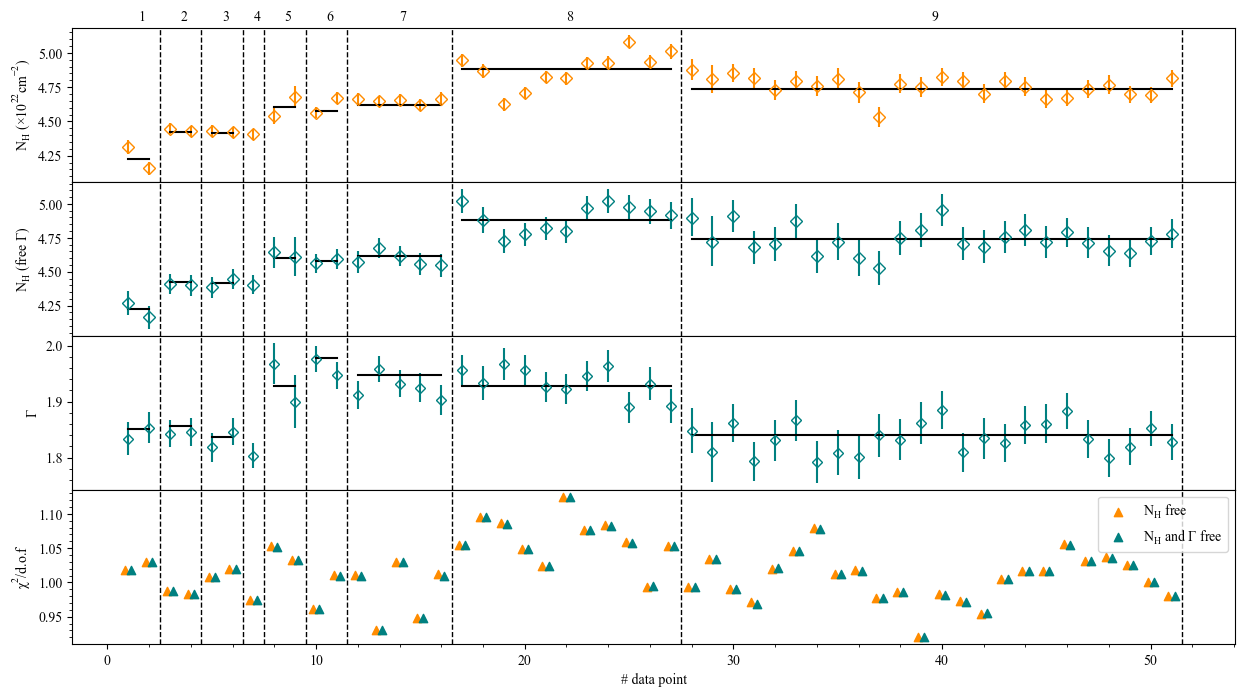

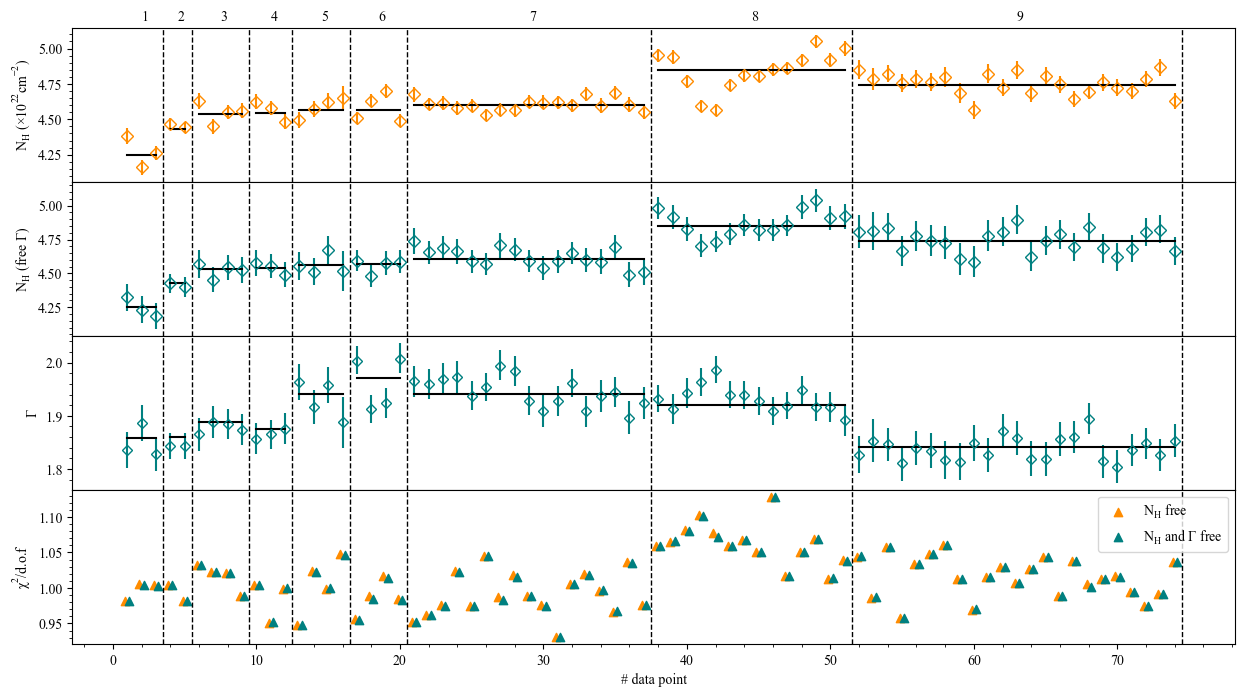

In [231]:
# Plotting N_H and Gamma light curve
plt.rcParams["font.family"] = "Times New Roman"

def plot_nh_light_curve(threshold):
    
    size=5
    
    data_point_start=1


    fig, axes = plt.subplots(4, 1, sharex=True, figsize=(15, 8))
    fig.subplots_adjust(hspace=0)


    total_data_points=[]
    iteration = 1
    total_values_nh_plot=[]
    
    for index, row in time_sorted_results_object.iterrows():

        if threshold in index:

            nh_values_nh_free=row['nh_values_nh_free']
            points_plot=list(range(data_point_start, data_point_start+len(nh_values_nh_free)))
            error_plot_nh_nh_free=row['error_plot_nh_nh_free']
            av_nh_val=row['av_nh_val']
            nh_values_nhgamma_free=row['nh_values_nhgamma_free']
            error_plot_nh_nhgamma_free=row['error_plot_nh_nhgamma_free']
            gamma_values_nhgamma_free=row['gamma_values_nhgamma_free']
            error_plot_gamma_nhgamma_free=row['error_plot_gamma_nhgamma_free']
            av_gamma_val=row['av_gamma_val']
            chi2_dof_nh_free=row['chi2_dof_nh_free']
            chi2_dof_nhgamma_free=row['chi2_dof_nhgamma_free']
            points_plot_offset=[x+0.15 for x in points_plot]
            points_plot_offset1=[x-0.15 for x in points_plot]
            
            total_values_nh_plot.extend(nh_values_nhgamma_free)


            axes[0].errorbar(points_plot,nh_values_nh_free , yerr=[error_plot_nh_nh_free[0], error_plot_nh_nh_free[1]], fmt='D', capsize=0, mfc='none', color='darkorange')
            axes[0].plot((points_plot[0],points_plot[len(points_plot)-1]),(av_nh_val,av_nh_val), color='k')
            axes[0].axvline(x=points_plot[len(points_plot)-1]+0.5, color='black', linestyle='--', linewidth=1)
            axes[0].set_ylabel(r'$\mathdefault{N_H}$'' (\u00D7'r'$\mathdefault {10^{22}cm^{-2}}$)')

            axes[0].yaxis.get_ticklocs(minor=True)    
            axes[0].minorticks_on()
            

            axes[1].errorbar(points_plot,nh_values_nhgamma_free, yerr=[error_plot_nh_nhgamma_free[0], error_plot_nh_nhgamma_free[1]], fmt='D', capsize=0, mfc='none', color='teal')
            axes[1].plot((points_plot[0],points_plot[len(points_plot)-1]),(av_nh_val,av_nh_val), color='k')
            axes[1].axvline(x=points_plot[len(points_plot)-1]+0.5, color='black', linestyle='--', linewidth=1)
            axes[1].set_ylabel(r'$\mathdefault{N_H}$'' (free \u0393)') 
            axes[1].yaxis.get_ticklocs(minor=True)    
            axes[1].minorticks_on()


            axes[2].errorbar(points_plot,gamma_values_nhgamma_free, yerr=[error_plot_gamma_nhgamma_free[0], error_plot_gamma_nhgamma_free[1]], fmt='D', capsize=0, mfc='none', markersize=5, color='teal')
            axes[2].plot((points_plot[0],points_plot[len(points_plot)-1]),(av_gamma_val,av_gamma_val), color='k')
            axes[2].axvline(x=points_plot[len(points_plot)-1]+0.5, color='black', linestyle='--', linewidth=1)
            axes[2].set_ylabel('\u0393')
            axes[2].yaxis.get_ticklocs(minor=True)    
            axes[2].minorticks_on()


            cd_nh_free=axes[3].scatter(points_plot_offset1, chi2_dof_nh_free, marker='^',color='darkorange')
            cd_nhgamma_free=axes[3].scatter(points_plot_offset, chi2_dof_nhgamma_free, marker='^',color='teal')
            axes[3].axvline(x=points_plot[len(points_plot)-1]+0.5, color='black', linestyle='--', linewidth=1)
            axes[3].set_ylabel('\u03C7'r'$\mathdefault{^2}$/d.o.f')
            axes[3].yaxis.get_ticklocs(minor=True)    
            axes[3].minorticks_on()


            iteration_center = sum(points_plot) / len(points_plot)     
            axes[0].annotate(f'{iteration}', xy=(iteration_center, 1), xytext=(0,5), xycoords=axes[0].get_xaxis_transform(),
                 ha="left", fontsize=10,
                 annotation_clip=True, textcoords=('offset points'))
            
        
            iteration += 1

            total_data_points.extend(points_plot)
            data_point_start=points_plot[len(points_plot)-1]+1
            


#     plt.xticks(total_data_points)
            
    cd_nh_free.set_label(r'$\mathdefault{N_H}$ free')
    cd_nhgamma_free.set_label(r'$\mathdefault{N_H}$'' and \u0393 free')
    axes[3].legend(loc='upper right')
    
    plt.xlabel('# data point')
    # plt.xlim(15,30)
    plt.savefig(f'N_H_gamma_light_curve_points_{source}_{threshold}.png')
    plt.show()

    
plot_nh_light_curve('cons')
plot_nh_light_curve('rel')

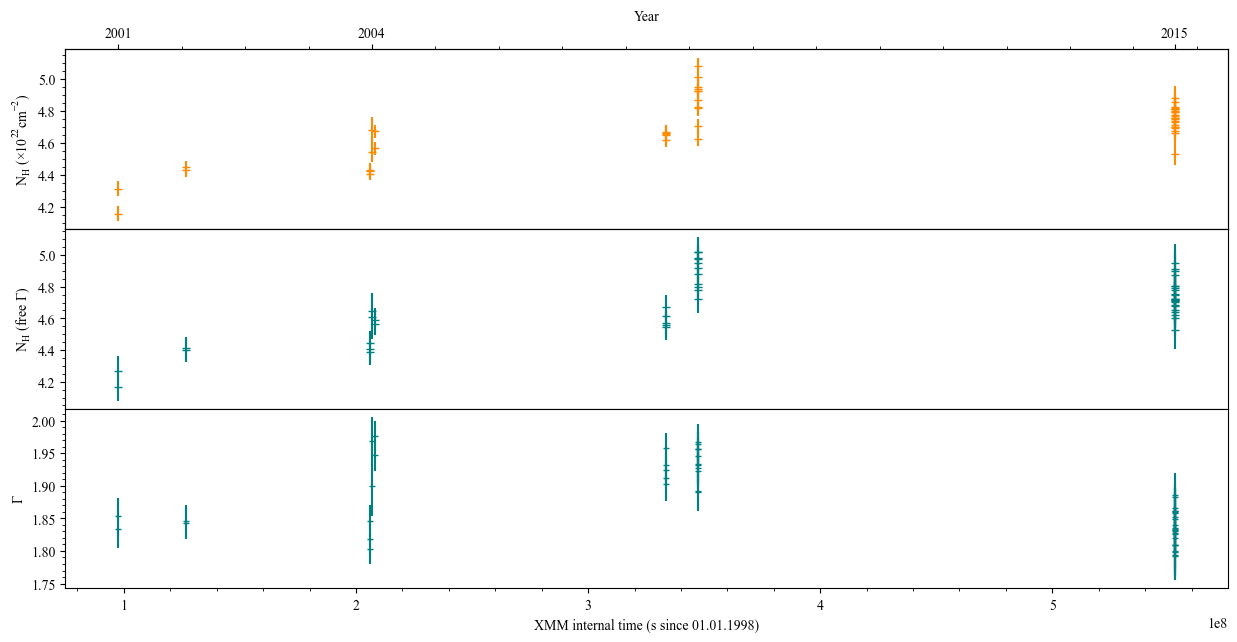

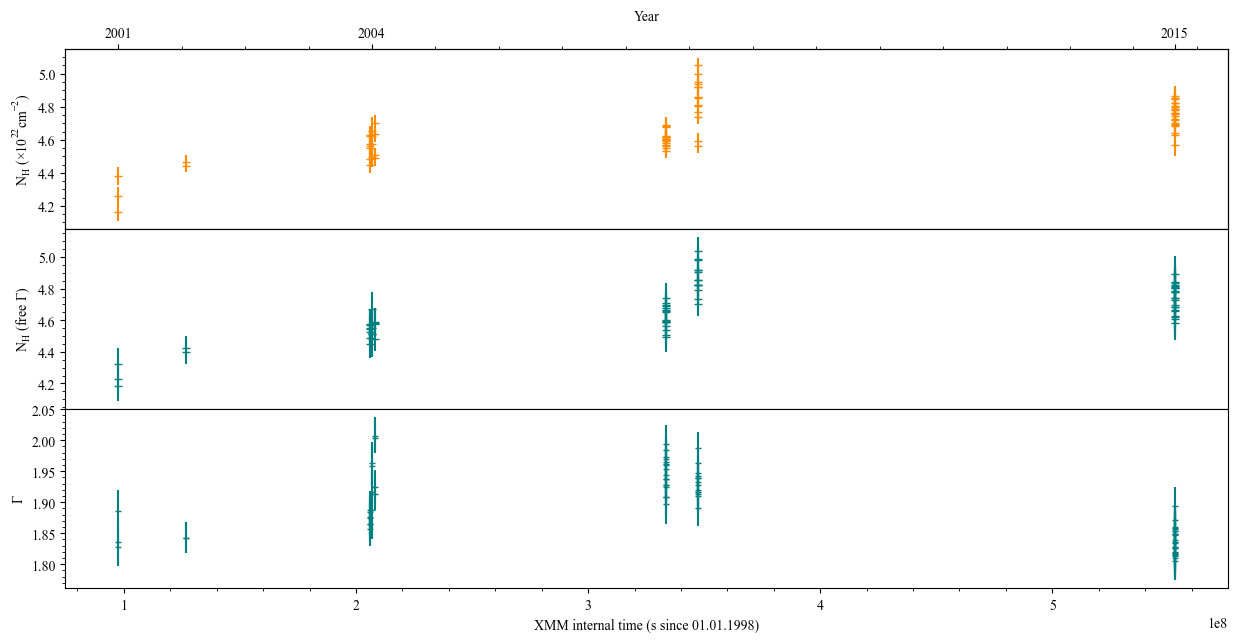

In [225]:
# Plotting N_H light curve in years

def plot_nh_years(threshold):
    
    fig, axes = plt.subplots(3, 1, sharex=True, figsize=(15, 7))
    fig.subplots_adjust(hspace=0)

    total_time_values=[]
    years=[]
    

    for index, row in time_sorted_results_object.iterrows():

        if threshold in index:

            nh_values_nh_free=row['nh_values_nh_free']
            time_values=row['time_values']
            error_plot_nh_nh_free=row['error_plot_nh_nh_free']
            av_nh_val=row['av_nh_val']
            nh_values_nhgamma_free=row['nh_values_nhgamma_free']
            error_plot_nh_nhgamma_free=row['error_plot_nh_nhgamma_free']
            gamma_values_nhgamma_free=row['gamma_values_nhgamma_free']
            error_plot_gamma_nhgamma_free=row['error_plot_gamma_nhgamma_free']
            av_gamma_val=row['av_gamma_val']
            
            
            t = Time(time_values, format='cxcsec', scale='tt')
            new_times=t.iso
            years_values=new_times[0].split('-')[0]
            years.append(years_values)
            

            axes[0].errorbar(time_values,nh_values_nh_free , yerr=[error_plot_nh_nh_free[0], error_plot_nh_nh_free[1]], fmt='_', capsize=0, mfc='none', color='darkorange')
            axes[0].set_ylabel(r'$\mathdefault{N_H}$'' (\u00D7'r'$\mathdefault {10^{22}cm^{-2}}$)')
            axes[0].yaxis.get_ticklocs(minor=True) 
            axes[0].minorticks_on()
        


            axes[1].errorbar(time_values,nh_values_nhgamma_free, yerr=[error_plot_nh_nhgamma_free[0], error_plot_nh_nhgamma_free[1]], fmt='_', capsize=0, mfc='none', color='teal')
            axes[1].set_ylabel(r'$\mathdefault{N_H}$'' (free \u0393)')
            axes[1].yaxis.get_ticklocs(minor=True)    
            axes[1].minorticks_on()


            axes[2].errorbar(time_values,gamma_values_nhgamma_free, yerr=[error_plot_gamma_nhgamma_free[0], error_plot_gamma_nhgamma_free[1]], fmt='_', capsize=0, mfc='none', markersize=5, color='teal')
            axes[2].set_ylabel('\u0393')
            axes[2].yaxis.get_ticklocs(minor=True)    
            axes[2].minorticks_on()


            mean_time_val=np.mean(time_values)
            total_time_values.append(mean_time_val)
            
    n = 4        
    ax2 = axes[0].twiny()
    ax2.set_xlim(axes[0].get_xlim())  
    ax2.set_xticks(total_time_values[::n])
    ax2.set_xticklabels(years[::n]) 
    ax2.minorticks_on()
    ax2.set_xlabel('Year')

     
    # plt.xticks(total_time_values) 
    axes[2].set_xlabel('XMM internal time (s since 01.01.1998)')
    plt.savefig(f'N_H_gamma_light_curve_time_{source}_{threshold}.png')
    plt.show()
    

plot_nh_years("cons")
plot_nh_years("rel")

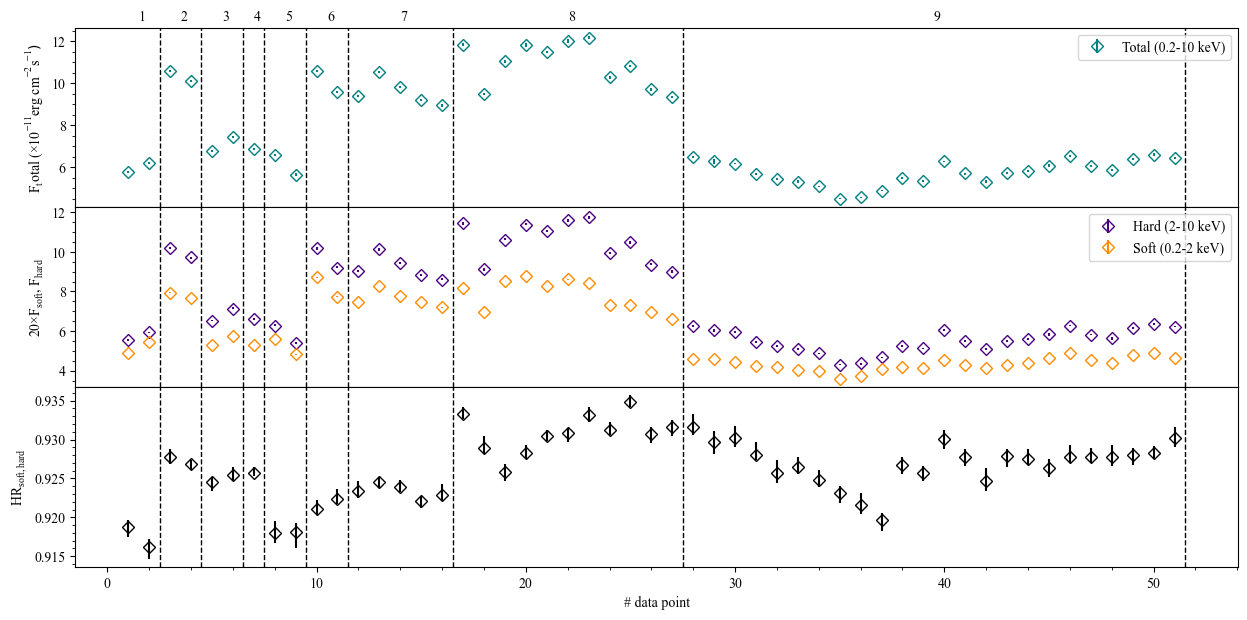

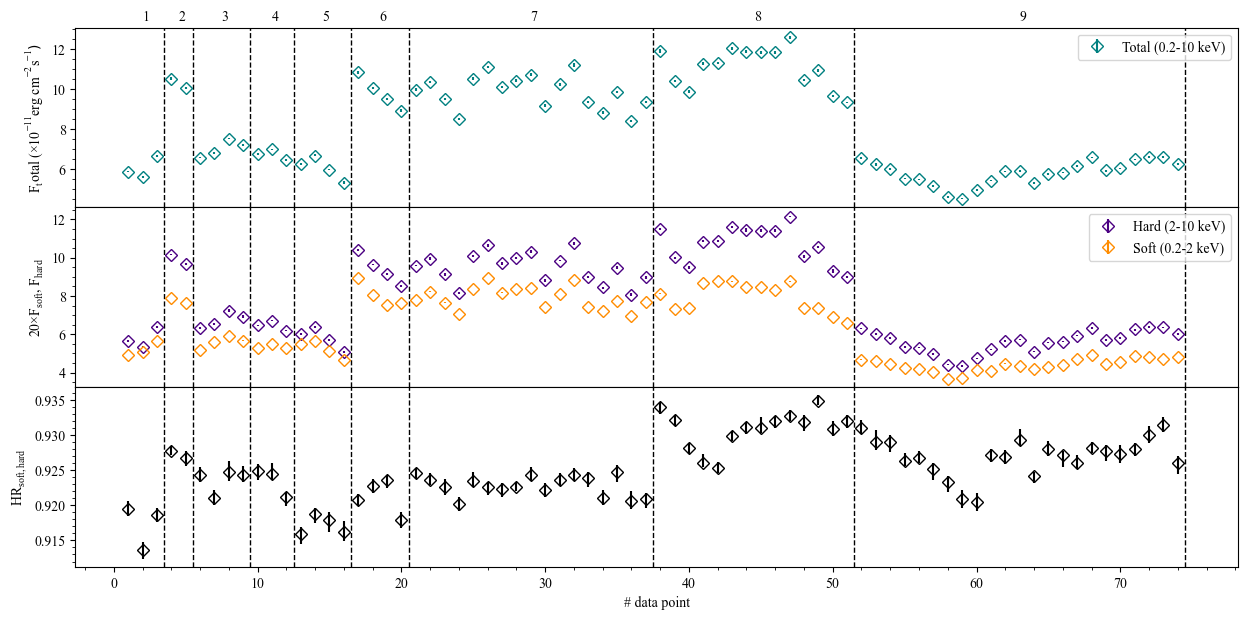

In [236]:
# Plotting fluxes

def plot_flux(threshold):
    
    data_point_start1=1

    fig, axes = plt.subplots(3, 1, sharex=True, figsize=(15, 7))
    fig.subplots_adjust(hspace=0)

    total_data_points1=[]
    iteration1 = 1
    
    for index, row in time_sorted_results_object.iterrows():
        
        if threshold in index:

            nh_values_nh_free=row['nh_values_nh_free']
            points_plot=list(range(data_point_start1, data_point_start1+len(nh_values_nh_free)))
            plot_flux_02_10=np.divide(row['plot_flux_02_10'],10**(-11))
            plot_flux_02_2=np.divide(row['plot_flux_02_2'],10**(-11))
            plot_flux_2_10=np.divide(row['plot_flux_2_10'],10**(-11))
            HR=row['HR']
            chi2_dof_nh_free=row['chi2_dof_nh_free']
            chi2_dof_nhgamma_free=row['chi2_dof_nhgamma_free']
            hr_uncertainities=row['hr_uncertainities']
            
            
            

            total=axes[0].errorbar(points_plot,plot_flux_02_10[0] , yerr=[plot_flux_02_10[1], plot_flux_02_10[2]], fmt='D', capsize=0, mfc='none', color='teal')
            axes[0].axvline(x=points_plot[len(points_plot)-1]+0.5, color='black', linestyle='--', linewidth=1)
#             axes[0].set_ylabel(r'F$_{\rm total}$'' (\u00D7'r'$10^{\rm -11}$''erg 'r'$\rm cm^{\rm -2} \rm s^{\rm-1})$')
            axes[0].set_ylabel(r'$\mathdefault{F_{total}}$'' (\u00D7'r'$\mathdefault{10^{-11}}$''erg 'r'$\mathdefault{cm^{-2}s^{-1}})$')
            axes[0].yaxis.get_ticklocs(minor=True)    
            axes[0].minorticks_on()
#             axes[0].yaxis.get_offset_text().set_visible(False)


            hard=axes[1].errorbar(points_plot,plot_flux_2_10[0] , yerr=[plot_flux_2_10[1], plot_flux_2_10[2]], fmt='D', capsize=0, mfc='none', color='indigo')
            soft=axes[1].errorbar(points_plot,np.multiply(plot_flux_02_2[0],20) , yerr=[plot_flux_02_2[1], plot_flux_02_2[2]], fmt='D', capsize=0, mfc='none', color='darkorange')
            axes[1].axvline(x=points_plot[len(points_plot)-1]+0.5, color='black', linestyle='--', linewidth=1)
            axes[1].set_ylabel('20\u00D7'r'$\mathdefault{F_{soft}}$'r', $\mathdefault{F_{hard}}$')
            axes[1].yaxis.get_ticklocs(minor=True)    
            axes[1].minorticks_on()
#             axes[1].yaxis.get_offset_text().set_visible(False)


            axes[2].errorbar(points_plot,HR, yerr=[hr_uncertainities[0], hr_uncertainities[1]], fmt='D', capsize=0, mfc='none', color='k')
            axes[2].axvline(x=points_plot[len(points_plot)-1]+0.5, color='black', linestyle='--', linewidth=1)
            axes[2].set_ylabel(r'$\mathdefault{HR_{soft, hard}}$')
            axes[2].yaxis.get_ticklocs(minor=True)    
            axes[2].minorticks_on()
            
            iteration_center1 = sum(points_plot) / len(points_plot)     
            axes[0].annotate(f'{iteration1}', xy=(iteration_center1, 1), xytext=(0,5), xycoords=axes[0].get_xaxis_transform(),
                 ha="left", fontsize=10,
                 annotation_clip=True, textcoords=('offset points'))
            
        
            iteration1 += 1


            total_data_points1.extend(points_plot)
            data_point_start1=points_plot[len(points_plot)-1]+1


    # plt.xticks(total_data_points)
    
    total.set_label(r'Total (0.2-10 keV)')
    axes[0].legend(loc='upper right')

    hard.set_label('Hard (2-10 keV)')
    soft.set_label('Soft (0.2-2 keV)')
    axes[1].legend(loc='upper right')

    # plt.xlim(30,50)
    plt.xlabel('# data point')
    plt.savefig(f'chi2_curve_{source}_{threshold}.png')
    plt.show()
    

plot_flux("cons")
plot_flux("rel") 